In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.decomposition import PCA

BASE_PATH = "/content/drive/MyDrive/ML_lab"
CSV_PATH = os.path.join(BASE_PATH, "BreaKHis_metadata.csv")
IMAGE_ROOT = os.path.join(BASE_PATH, "BreaKHis_v1")

IMAGE_SIZE = (16, 16)
SAMPLES_PER_CLASS = 100
RANDOM_STATE = 42
TEST_SIZE = 0.20

In [ ]:
drive.mount("/content/drive")

metadata = pd.read_csv(CSV_PATH)

metadata["label"] = metadata["filename"].apply(
    lambda path: (
        "benign" if "/benign/" in str(path).lower()
        else "malignant" if "/malignant/" in str(path).lower()
        else None
    )
)

metadata = metadata.dropna(subset=["label"]).reset_index(drop=True)

print("Metadata shape:", metadata.shape)
print("\nAvailable images by class:")
print(metadata["label"].value_counts())

Mounted at /content/drive
Metadata shape: (39545, 5)

Available images by class:
label
malignant    27145
benign       12400
Name: count, dtype: int64


In [ ]:
def locate_image(filename):
    relative_path = str(filename).replace("\\", "/").lstrip("/")

    candidates = [
        os.path.join(BASE_PATH, relative_path),
        os.path.join(IMAGE_ROOT, relative_path)
    ]

    if relative_path.startswith("BreaKHis_v1/"):
        short_path = relative_path.split("BreaKHis_v1/", 1)[1]
        candidates.extend([
            os.path.join(IMAGE_ROOT, short_path),
            os.path.join(IMAGE_ROOT, "BreaKHis_v1", short_path)
        ])

    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate

    return None


def load_project_dataset(dataframe):
    features = []
    labels = []
    missing_files = 0

    for _, row in dataframe.iterrows():
        image_path = locate_image(row["filename"])

        if image_path is None:
            missing_files += 1
            continue

        try:
            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize(IMAGE_SIZE)
                image_array = np.asarray(image, dtype=np.float32) / 255.0

            features.append(image_array.flatten())
            labels.append(1 if row["label"] == "malignant" else 0)

        except (OSError, ValueError):
            missing_files += 1

    X = np.asarray(features, dtype=np.float32).reshape(-1, 256)
    y = np.asarray(labels, dtype=np.int64)

    return X, y, missing_files

In [ ]:
class_counts = metadata["label"].value_counts()

if any(class_counts.get(label, 0) < SAMPLES_PER_CLASS
       for label in ["benign", "malignant"]):
    raise ValueError("Not enough images available in both classes.")

project_subset = (
    metadata.groupby("label", group_keys=False)
    .sample(n=SAMPLES_PER_CLASS, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

X_project, y_project, missing_files = load_project_dataset(project_subset)

print("Loaded dataset shape:", X_project.shape)
print("\nClass distribution:")
print(
    pd.Series(y_project)
    .value_counts()
    .rename(index={0: "Benign", 1: "Malignant"})
)
print("\nImages not loaded:", missing_files)

if len(X_project) != 200:
    raise ValueError(
        f"Expected 200 loaded images, but loaded {len(X_project)}. "
        "Check the dataset paths and missing files."
    )

Loaded dataset shape: (200, 256)

Class distribution:
Benign       100
Malignant    100
Name: count, dtype: int64

Images not loaded: 0


In [ ]:
# A1 function: stacking classifier
def run_stacking_experiments(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    base_models = [
        ("knn", Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ])),
        ("decision_tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
        ("mlp", Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(50,),
                max_iter=1000,
                random_state=RANDOM_STATE
            ))
        ]))
    ]

    final_estimators = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=3, random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE
        )
    }

    results = []
    trained_models = {}

    for name, estimator in final_estimators.items():
        model = StackingClassifier(
            estimators=base_models,
            final_estimator=estimator,
            cv=5
        )

        start_time = time.perf_counter()
        model.fit(X_train, y_train)
        training_time = time.perf_counter() - start_time

        predictions = model.predict(X_test)

        results.append({
            "Final Estimator": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Training Time (s)": training_time
        })

        trained_models[name] = model

    return pd.DataFrame(results), trained_models

In [ ]:
# Feature Correlation Analysis and Heatmap
def feature_correlation_analysis(X, top_n=20):
    feature_names = [f"Pixel_{i + 1}" for i in range(X.shape[1])]
    feature_data = pd.DataFrame(X, columns=feature_names)

    correlation_matrix = feature_data.corr()

    feature_variance = feature_data.var().sort_values(ascending=False)
    selected_features = feature_variance.head(
        min(top_n, X.shape[1])
    ).index.tolist()

    selected_correlation = correlation_matrix.loc[
        selected_features, selected_features
    ]

    upper_triangle = correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )

    strongest_correlations = (
        upper_triangle.stack()
        .rename("Correlation")
        .reset_index()
        .rename(columns={
            "level_0": "Feature 1",
            "level_1": "Feature 2"
        })
    )

    strongest_correlations["Absolute Correlation"] = (
        strongest_correlations["Correlation"].abs()
    )

    strongest_correlations = strongest_correlations.sort_values(
        "Absolute Correlation", ascending=False
    ).head(10)

    return correlation_matrix, selected_correlation, strongest_correlations

In [ ]:
# PCA Dimensionality Reduction
def compare_pca_models(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y
    )

    models = {
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "MLP": MLPClassifier(
            hidden_layer_sizes=(50,),
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    }

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    pca_full = PCA()
    pca_full.fit(X_train_scaled)

    cumulative_variance = np.cumsum(
        pca_full.explained_variance_ratio_
    )

    n_components = np.searchsorted(
        cumulative_variance, 0.99
    ) + 1

    pca = PCA(n_components=n_components)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    results = []

    for name, classifier in models.items():
        classifier_original = Pipeline([
            ("scaler", StandardScaler()),
            ("model", classifier)
        ])

        classifier_original.fit(X_train, y_train)
        original_predictions = classifier_original.predict(X_test)

        results.append({
            "Model": name,
            "Features": "Original",
            "Feature Count": X_train.shape[1],
            "Accuracy": accuracy_score(
                y_test, original_predictions
            ),
            "Precision": precision_score(
                y_test, original_predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, original_predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, original_predictions, zero_division=0
            )
        })

        classifier_pca = Pipeline([
            ("model", classifier.__class__(**classifier.get_params()))
        ])

        classifier_pca.fit(X_train_pca, y_train)
        pca_predictions = classifier_pca.predict(X_test_pca)

        results.append({
            "Model": name,
            "Features": "PCA (99%)",
            "Feature Count": n_components,
            "Accuracy": accuracy_score(y_test, pca_predictions),
            "Precision": precision_score(
                y_test, pca_predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, pca_predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, pca_predictions, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)

    return results_df, n_components, cumulative_variance

A1: Stacking Classifier Results


,Final Estimator,Accuracy,Precision,Recall,F1 Score,Training Time (s)
0,Logistic Regression,0.500,0.5000,0.40,0.4444,2.2376
1,Decision Tree,0.525,0.5263,0.50,0.5128,13.8452
2,Random Forest,0.475,0.4737,0.45,0.4615,11.2326


Best Final Estimator: Decision Tree

A2: Feature Correlation Analysis
Correlation Matrix Shape: (256, 256)

Top 10 Most Strongly Correlated Feature Pairs:


,Feature 1,Feature 2,Correlation,Absolute Correlation
13934,Pixel_63,Pixel_79,0.9225,0.9225
32127,Pixel_224,Pixel_240,0.9181,0.9181
24270,Pixel_127,Pixel_143,0.9147,0.9147
21924,Pixel_110,Pixel_126,0.9142,0.9142
10289,Pixel_45,Pixel_61,0.9137,0.9137
13740,Pixel_62,Pixel_78,0.9125,0.9125
32519,Pixel_240,Pixel_256,0.9122,0.9122
1779,Pixel_8,Pixel_24,0.9087,0.9087
3252,Pixel_14,Pixel_30,0.9044,0.9044
22070,Pixel_111,Pixel_127,0.9042,0.9042


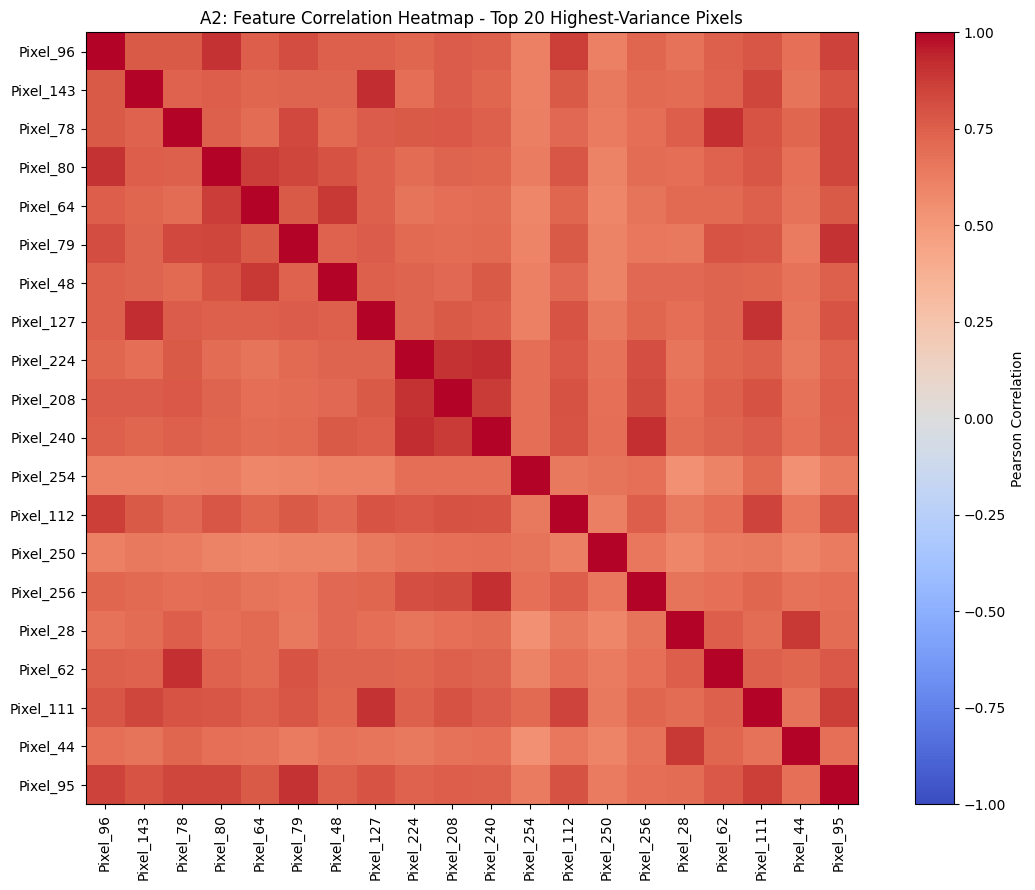

A3: Original Features vs PCA-Reduced Features
Original feature count: 256
Components required for 99% variance: 98
Cumulative explained variance: 0.9901


,Model,Features,Feature Count,Accuracy,Precision,Recall,F1 Score
0,KNN,Original,256,0.325,0.3600,0.45,0.4000
1,KNN,PCA (99%),98,0.350,0.3750,0.45,0.4091
2,Decision Tree,Original,256,0.500,0.5000,0.45,0.4737
3,Decision Tree,PCA (99%),98,0.475,0.4783,0.55,0.5116
4,MLP,Original,256,0.550,0.5417,0.65,0.5909
5,MLP,PCA (99%),98,0.475,0.4762,0.50,0.4878


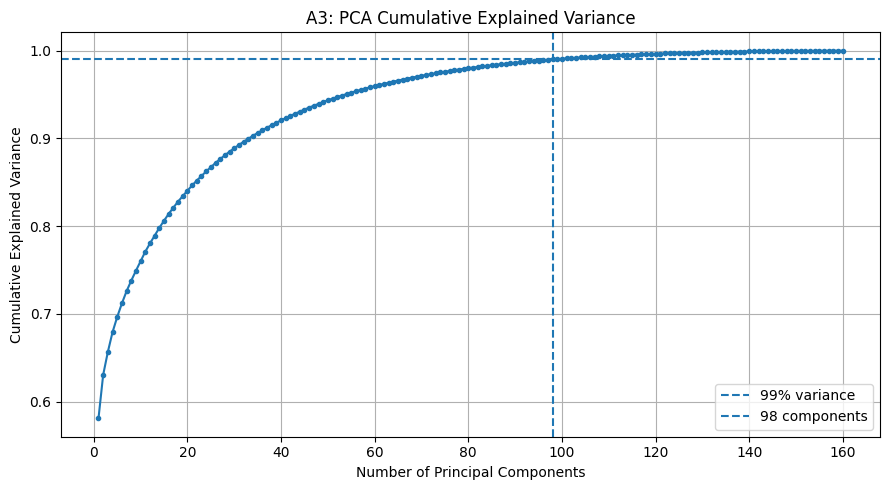

In [ ]:
# Main Function
results_df, stacking_models = run_stacking_experiments(
    X_project, y_project
)

print("A1: Stacking Classifier Results")
display(results_df.round(4))

best_model = results_df.loc[
    results_df["F1 Score"].idxmax(), "Final Estimator"
]

print("Best Final Estimator:", best_model)


correlation_matrix, selected_correlation, strongest_correlations = (
    feature_correlation_analysis(X_project, top_n=20)
)

print("\nA2: Feature Correlation Analysis")
print("Correlation Matrix Shape:", correlation_matrix.shape)

print("\nTop 10 Most Strongly Correlated Feature Pairs:")
display(strongest_correlations.round(4))

plt.figure(figsize=(12, 9))
plt.imshow(
    selected_correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)
plt.colorbar(label="Pearson Correlation")
plt.xticks(
    range(len(selected_correlation.columns)),
    selected_correlation.columns,
    rotation=90
)
plt.yticks(
    range(len(selected_correlation.index)),
    selected_correlation.index
)
plt.title("A2: Feature Correlation Heatmap - Top 20 Highest-Variance Pixels")
plt.tight_layout()
plt.show()


results_a3, n_components, cumulative_variance = compare_pca_models(
    X_project, y_project
)

print("A3: Original Features vs PCA-Reduced Features")
print("Original feature count:", X_project.shape[1])
print("Components required for 99% variance:", n_components)
print(
    "Cumulative explained variance:",
    round(cumulative_variance[n_components - 1], 4)
)

display(results_a3.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="."
)
plt.axhline(y=0.99, linestyle="--", label="99% variance")
plt.axvline(
    x=n_components,
    linestyle="--",
    label=f"{n_components} components"
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("A3: PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()